### 1. Configuration

Run after `2_preprocessing.ipynb`. Read its saved splits, images, targets, masks and labels without changing them. Train the backbone and regression head first, then freeze the backbone and train the classification head. Results go into a new folder.

In [1]:
from pathlib import Path
from datetime import datetime
import gc
import json
import random
import shutil
import numpy as np
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import confusion_matrix, average_precision_score, roc_auc_score, roc_curve
from scipy.special import expit
import matplotlib.pyplot as plt

from model import Model, ClassificationHead

DATA = Path("dataset")
OUT = Path("training")
SEEDS = (2026, 2027, 2028)
DEVICE = "cuda"
LR, WEIGHT_DECAY = 3e-4, 1e-4
REGRESSION_BATCH, CLASSIFICATION_BATCH = 32, 64
MAX_EPOCHS, CHECKS, PATIENCE = 100, 5, 15
CHANNELS = ("pressure", "thermistor", "thorax", "abdomen")

assert torch.cuda.is_available(), "A CUDA GPU is required"
splits = json.loads((DATA / "splits.json").read_text())
torch.set_num_threads(4)
torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def save_json(path, values):
    temporary = path.with_suffix(".tmp.json")
    temporary.write_text(json.dumps(values, indent=2, allow_nan=False))
    temporary.replace(path)


def save_checkpoint(path, **state):
    temporary = path.with_suffix(".tmp.pt")
    torch.save(state, temporary)
    temporary.replace(path)


### 2. Saved windows

In [3]:
class Windows(Dataset):
    def __init__(self, patients, classification=False):
        self.patients, self.classification = patients, classification
        self.paths, targets, masks, labels, ids = [], [], [], [], []
        self.counts = np.zeros((len(patients), 4), dtype=np.int64)
        for patient_id, patient in enumerate(patients):
            for path in (DATA / "images" / patient).iterdir():
                with np.load(DATA / "signals" / patient / f"{path.stem}.npz") as data:
                    label = int(data["label"])
                    if classification and label < 0:
                        continue
                    if not classification:
                        target, valid = data["target"].copy(), data["valid"].astype(bool)
                        target[~valid] = 0
                        targets.append(target)
                        masks.append(valid)
                        self.counts[patient_id] += valid.sum(0)
                self.paths.append(path)
                labels.append(label)
                ids.append(patient_id)
        self.labels, self.ids = np.array(labels, dtype=np.float32), np.array(ids)
        if classification:
            counts = np.bincount(self.ids, minlength=len(patients))
            assert (counts > 0).all(), "A patient has no classification windows"
            self.weights = len(self) / (len(patients) * counts)
        else:
            self.targets, self.valid = np.stack(targets), np.stack(masks)
            available = self.counts > 0
            assert available.any(1).all(), "A patient has no valid regression targets"
            denominator = len(patients) * available.sum(1, keepdims=True) * self.counts
            self.weights = np.divide(len(self), denominator, out=np.zeros_like(denominator, dtype=float), where=available)
        print(f"Loaded {len(patients)} patients / {len(self)} windows")

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        image = np.load(self.paths[i]).astype(np.float32)[None]
        if self.classification:
            return image, self.labels[i], self.ids[i]
        return image, self.targets[i], self.valid[i], self.ids[i]


### 3. Regression evaluation

Average valid time samples within each patient's channel, then available channels, then patients. Pearson is computed within each window and averaged in the same order; constant signals are excluded. No phase or polarity adjustment is applied here.

In [ ]:
def mean(values):
    values = [value for value in values if value is not None]
    return float(np.mean(values)) if values else None


def regression_errors(prediction, target, valid):
    count = valid.sum(1)
    return nn.functional.huber_loss(prediction, target, reduction="none").masked_fill(~valid, 0).sum(1), count

def correlation(prediction, target, valid):
    p, t = prediction.masked_fill(~valid, 0), target.masked_fill(~valid, 0)
    sp, st, count = p.sum(1), t.sum(1), valid.sum(1).clamp(min=1)
    vp, vt = p.square().sum(1) - sp.square()/count, t.square().sum(1) - st.square()/count
    cov = (p*t).sum(1) - st*sp/count
    corr = cov / (vp.clamp(min=0) * vt.clamp(min=0)).sqrt().clamp(min=1e-8)
    good = (valid.sum(1) >= 2) & (vp > 1e-8) & (vt > 1e-8)
    return corr.masked_fill(~good, 0), good

@torch.inference_mode()
def evaluate_regression(model, batches, patients):
    model.eval()
    sums = torch.zeros((len(patients), 4, 4), device=DEVICE, dtype=torch.float64)
    for image, target, valid, ids in batches:
        image, target, valid, ids = [x.to(DEVICE, non_blocking=True) for x in (image, target, valid, ids)]
        with torch.autocast("cuda", dtype=torch.bfloat16):
            prediction = model(image).transpose(1, 2).float()
        loss, count = regression_errors(prediction, target, valid)
        corr, good = correlation(prediction, target, valid)
        values = torch.stack((loss, count, corr, good.double()), -1)
        sums.index_add_(0, ids, values)
    patients_result = {}
    for patient, values in zip(patients, sums.cpu().numpy()):
        patients_result[patient] = {
            channel: dict(huber=float(loss / count), pearson= corr/good if good else None)
            if count else None for channel, (loss, count, corr, good) in zip(CHANNELS, values)
        }
    channels = {c: {key: mean([p[c][key] for p in patients_result.values() if p[c] is not None])
                    for key in ("huber", "pearson")} for c in CHANNELS}
    overall = {key: mean([mean([v[key] for v in p.values() if v is not None])
                    for p in patients_result.values()]) for key in ("huber", "pearson")}
    return dict(loss=overall["huber"], **overall, channels=channels, patients=patients_result)

### 4. Classification evaluation

Use the saved labels: exclude `-1`, and keep `0` and `1` unchanged. Select the checkpoint by patient-balanced BCE. Select one threshold using validation mean patient balanced accuracy, then apply it unchanged to test. Patients with only one class do not contribute to balanced accuracy or AUROC.

In [ ]:
def classification_metrics(logits, labels, ids, patients, threshold=0):
    def calculate(take):
        z, y = logits[take], labels[take]
        predicted = z >= threshold
        tn, fp, fn, tp = confusion_matrix(y, predicted, labels=[0, 1]).ravel()
        both = bool((y == 0).any() and (y == 1).any())
        return dict(windows=len(y), positive=int(y.sum()),
            bce=float(np.mean(np.logaddexp(0, z) - y * z)), 
            accuracy=float(np.mean(predicted == y)),
            balanced_accuracy=float((tp / (tp + fn) + tn / (tn + fp)) / 2) if both else None,
            sensitivity=float(tp / (tp + fn)) if tp + fn else None,
            specificity=float(tn / (tn + fp)) if tn + fp else None,
            precision=float(tp / (tp + fp)) if tp + fp else 0.,
            f1=float(2 * tp / (2 * tp + fp + fn)) if 2 * tp + fp + fn else 0.,
            ap=float(average_precision_score(y, expit(z))) if y.sum() else None,
            auroc=float(roc_auc_score(y, expit(z))) if both else None,
            confusion_matrix=[[int(tn), int(fp)], [int(fn), int(tp)]])
    per_patient = {p: calculate(ids == i) for i, p in enumerate(patients) if (ids == i).any()}
    keys = ("bce", "accuracy", "balanced_accuracy", "sensitivity", "specificity", "precision", "f1", "ap", "auroc")
    averages = {key: mean([p[key] for p in per_patient.values()]) for key in keys}
    return dict(loss=averages["bce"], patient_mean=averages, pooled=calculate(np.ones(len(labels), bool)), patients=per_patient)


@torch.inference_mode()
def predict_classification(model, batches):
    model.eval()
    logits, labels, ids = [], [], []
    for features, label, patient in batches:
        with torch.autocast("cuda", dtype=torch.bfloat16, enabled=features.ndim == 4):
            prediction = model(features.to(DEVICE, non_blocking=True))
        logits.append(prediction.float().squeeze(1).cpu().numpy())
        labels.append(label.numpy())
        ids.append(patient.numpy())
    return np.concatenate(logits).astype(float), np.concatenate(labels).astype(int), np.concatenate(ids)

def choose_threshold(logits, labels, ids):
    pos = np.bincount(ids, weights=labels)
    neg = np.bincount(ids) - pos
    valid = (pos[ids] > 0) & (neg[ids] > 0)
    y, z, p = labels[valid], logits[valid], ids[valid]
    weights = np.where(y, 1 / pos[p], 1 / neg[p])
    fpr, tpr, thresholds = roc_curve(y, z, sample_weight=weights)
    return float(thresholds[np.argmax(tpr - fpr)])

### 5. Training

AdamW, gradient clipping at 1, validation every fifth of an epoch. Stop after 15 checks without a relative improvement of at least 0.1%; always save the absolute minimum validation loss. Resume from the last completed check.

In [ ]:
def regression_loss(model, batch, weights):
    image, target, valid, ids = batch
    with torch.autocast("cuda", dtype=torch.bfloat16):
        prediction = model(image).transpose(1, 2)
    losses = nn.functional.huber_loss(prediction.float(), target, reduction="none").masked_fill(~valid, 0)
    return (losses.sum(1) * weights[ids]).sum() / len(image)


def classification_loss(model, batch, weights):
    features, label, ids = batch
    with torch.autocast("cuda", dtype=torch.bfloat16, enabled=features.ndim == 4):
        logits = model(features).squeeze(1)
    losses = nn.functional.binary_cross_entropy_with_logits(logits.float(), label, reduction="none")
    return (losses * weights[ids]).mean()


def fit(model, datasets, folder, phase):
    folder.mkdir(parents=True, exist_ok=True)

    regression = phase == "regression"
    batch_size = REGRESSION_BATCH if regression else CLASSIFICATION_BATCH
    loss_fn = regression_loss if regression else classification_loss

    train, val = datasets["train"], datasets["validation"]
    train_loader = DataLoader(train, batch_size=batch_size, shuffle=True, num_workers=4, pin_memory=True, persistent_workers=True)
    val_loader = DataLoader(val, batch_size=batch_size, shuffle=False, num_workers=4, pin_memory=True, persistent_workers=True)

    weights = torch.as_tensor(train.weights, device=DEVICE, dtype=torch.float32)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

    best, stale, best_epoch = float("inf"), 0, 0
    checkpoint_every = len(train_loader)//CHECKS
    history = []

    for epoch in range(MAX_EPOCHS):
        model.train()
        total, count = 0., 0
        for i, batch in enumerate(train_loader, start=1):
            batch = [x.to(DEVICE, non_blocking=True) for x in batch]
            loss = loss_fn(model, batch, weights)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1., error_if_nonfinite=True)
            optimizer.step()
            total += loss.item() * len(batch[0])
            count += len(batch[0])
            if i % checkpoint_every == 0 or i == len(train_loader):
                current_epoch = epoch + i / len(train_loader)
                if regression:
                    metrics = evaluate_regression(model, val_loader, val.patients)
                else:
                    metrics = classification_metrics(*predict_classification(model, val_loader), val.patients)

                value = metrics["loss"]
                if value < best:
                    best, stale, best_epoch = value, 0, current_epoch
                    save_checkpoint(folder / "best.pt", model=model.state_dict(), epoch=best_epoch)
                else:
                    stale += 1

                history.append(dict(epoch=current_epoch, train_loss=total / count, validation=metrics, stale=stale))
                save_json(folder / "history.json", history)

                print(f"{phase} {current_epoch:.2f}: train={total/count:.5f}, validation={value:.5f}, patience={stale}/{PATIENCE}", flush=True)
                model.train()
                total, count = 0., 0
        if stale >= PATIENCE:
            break

    checkpoint = torch.load(folder / "best.pt", map_location="cpu", weights_only=False)
    model.load_state_dict(checkpoint["model"])
    return best_epoch

### 6. Frozen features

Extract the best regression backbone's features once. Store them temporarily on the internal disk in float16; train the classification head in float32. The saved label determines which windows are eligible.

In [ ]:
class Features(Dataset):
    def __init__(self, path, windows, indices):
        self.features = np.load(path, mmap_mode="r")
        self.indices = indices
        self.labels = windows.labels[indices].astype(np.float32)
        self.ids = windows.ids[indices]
        self.patients = windows.patients
        counts = np.bincount(self.ids, minlength=len(self.patients))
        self.weights = len(indices) / (len(counts) * counts)

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        return self.features[i].astype(np.float32), self.labels[i], self.ids[i]


@torch.inference_mode()
def extract_features(backbone, datasets, folder):
    backbone.eval().requires_grad_(False)
    features = {}
    for part, windows in datasets.items():
        indices = np.flatnonzero(windows.labels >= 0)
        path = folder / f"{part}_features.npy"
        array = np.lib.format.open_memmap(path, mode="w+", dtype=np.float16, shape=(len(indices), 128, 600))
        at = 0
        batches = DataLoader(windows, batch_size=REGRESSION_BATCH, sampler=indices, num_workers=4, pin_memory=True)
        for image, _, _, _ in batches:
            with torch.autocast("cuda", dtype=torch.bfloat16):
                values = backbone(image.to(DEVICE, non_blocking=True))
            values = values.float().cpu().numpy().astype(np.float16)
            array[at:at + len(values)] = values
            at += len(values)
        array.flush()
        del array
        features[part] = Features(path, windows, indices)
        print(f"{part}: {len(indices)} classification windows", flush=True)
    return features

### 7. Train and evaluate

Keep the saved patient splits unchanged. Evaluate test only after selecting the checkpoint and classification threshold on validation. Save checkpoints, histories, per-patient metrics and classification predictions. The combined model can discard its regression head at inference.

In [8]:
OUT.mkdir(parents=True, exist_ok=True)
(OUT / "model.py").write_text(Path("model.py").read_text())

for seed in SEEDS:
    folder = OUT / f"split{seed}" / "frozen_backbone"
    folder.mkdir(parents=True, exist_ok=True)
    if (folder / "results.json").exists():
        continue
    split = splits[str(seed)]
    assert len(set(sum(split.values(), []))) == sum(map(len, split.values())), "Patient overlap between sets"
    datasets = {part: Windows(patients) for part, patients in split.items()}
    set_seed(seed)
    model = Model().to(DEVICE)

    regression = nn.Sequential(model.backbone, model.regression_head)
    regression_epoch = fit(regression, datasets, folder / "regression", "regression")
    regression_results = dict(best_epoch=regression_epoch)
    for part, data in datasets.items():
        batches = DataLoader(data, batch_size=REGRESSION_BATCH, num_workers=4, pin_memory=True)
        regression_results[part] = evaluate_regression(regression, batches, data.patients)

    features = extract_features(model.backbone, datasets, folder)
    set_seed(seed)
    model.classification_head = ClassificationHead().to(DEVICE)
    classification_epoch = fit(model.classification_head, features, folder / "classification", "classification")
    batches = DataLoader(features["validation"], batch_size=CLASSIFICATION_BATCH, num_workers=4, pin_memory=True)
    threshold = choose_threshold(*predict_classification(model.classification_head, batches))

    classification_results = dict(best_epoch=classification_epoch, threshold_logit=threshold)
    for part, data in features.items():
        batches = DataLoader(data, batch_size=CLASSIFICATION_BATCH, num_workers=4, pin_memory=True)
        logits, labels, ids = predict_classification(model.classification_head, batches)
        classification_results[part] = classification_metrics(logits, labels, ids, data.patients, threshold)
        np.savez_compressed(folder / "classification" / f"{part}_predictions.npz",
                            logits=logits, labels=labels, patient_ids=ids, window_indices=data.indices,
                            starts=[int(datasets[part].paths[i].stem) for i in data.indices])

    torch.save(dict(model=model.state_dict(), threshold_logit=threshold, split=split), folder / "model.pt")
    save_json(folder / "results.json", dict(regression=regression_results, classification=classification_results))
    print(f"Split {seed} test:", classification_results["test"]["patient_mean"], flush=True)
    del batches, data, features, datasets, regression, model
    gc.collect()
    torch.cuda.empty_cache()
    for path in folder.glob("*_features.npy"):
        path.unlink()


### 8. Loss curves

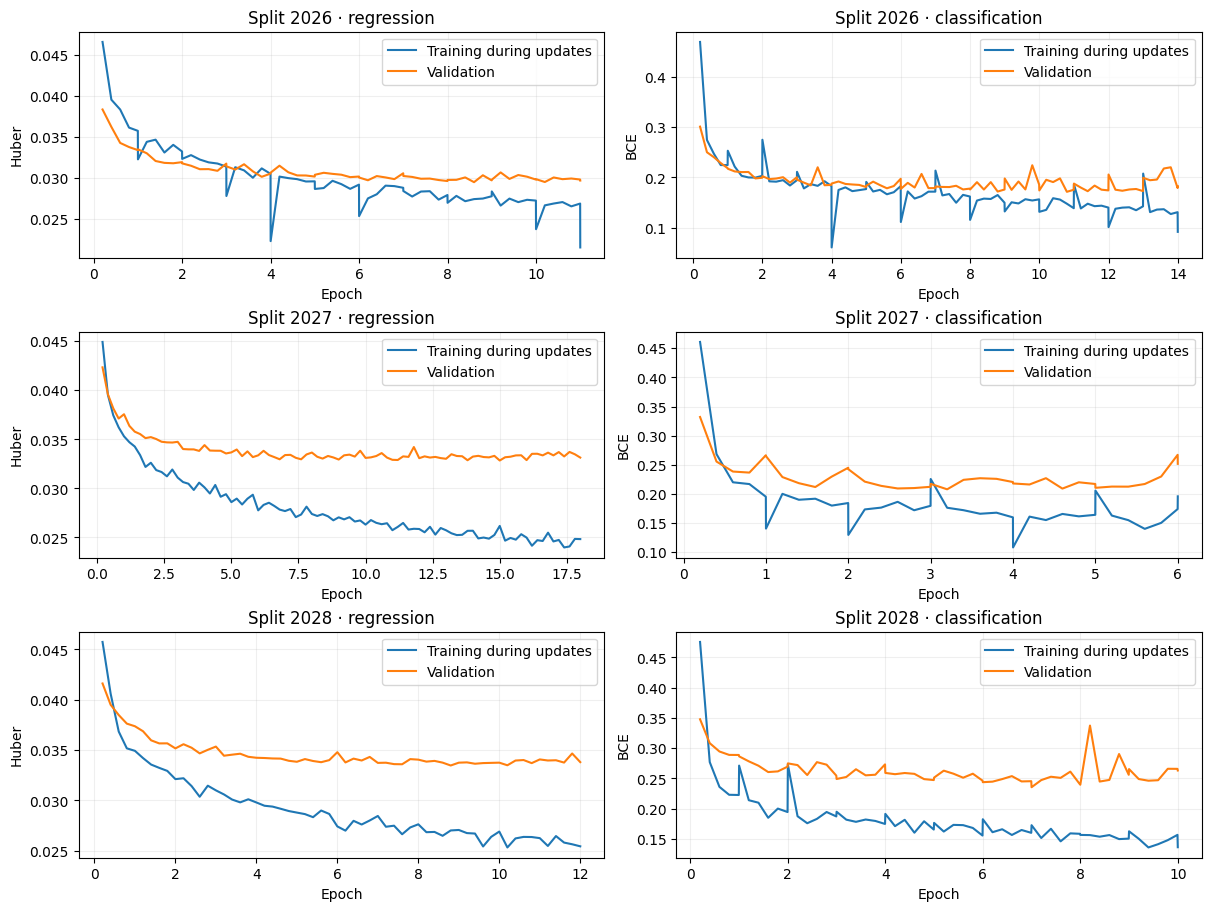

In [9]:
fig, axes = plt.subplots(len(SEEDS), 2, figsize=(12, 3 * len(SEEDS)), squeeze=False, layout="constrained")
for row, seed in enumerate(SEEDS):
    for col, phase in enumerate(("regression", "classification")):
        history = json.loads((OUT / f"split{seed}" / "frozen_backbone" / phase / "history.json").read_text())
        epochs = [h["epoch"] for h in history]
        axes[row, col].plot(epochs, [h["train_loss"] for h in history], label="Training during updates")
        axes[row, col].plot(epochs, [h["validation"]["loss"] for h in history], label="Validation")
        axes[row, col].set(title=f"Split {seed} · {phase}", xlabel="Epoch", ylabel="Huber" if col == 0 else "BCE")
        axes[row, col].grid(alpha=.2)
        axes[row, col].legend()
fig.savefig(OUT / "loss_curves.png", dpi=160)
plt.show()

In [10]:
# Train the same classifier directly from audio, without regression pretraining.
for seed in SEEDS:
    strategy = OUT / f"split{seed}" / "from_scratch"
    folder = strategy / "classification"
    folder.mkdir(parents=True, exist_ok=True)
    if (strategy / "results.json").exists():
        continue
    split = splits[str(seed)]
    datasets = {part: Windows(patients, classification=True) for part, patients in split.items()}
    set_seed(seed)
    model = Model().to(DEVICE)
    set_seed(seed)
    model = nn.Sequential(model.backbone, ClassificationHead().to(DEVICE))
    best_epoch = fit(model, datasets, folder, "classification")
    batches = DataLoader(datasets["validation"], batch_size=CLASSIFICATION_BATCH, num_workers=4, pin_memory=True)
    threshold = choose_threshold(*predict_classification(model, batches))

    results = dict(best_epoch=best_epoch, threshold_logit=threshold)
    for part, data in datasets.items():
        batches = DataLoader(data, batch_size=CLASSIFICATION_BATCH, num_workers=4, pin_memory=True)
        logits, labels, ids = predict_classification(model, batches)
        results[part] = classification_metrics(logits, labels, ids, data.patients, threshold)
        np.savez_compressed(folder / f"{part}_predictions.npz", logits=logits, labels=labels,
                            patient_ids=ids,
                            starts=[int(path.stem) for path in data.paths])
    torch.save(dict(model=model.state_dict(), threshold_logit=threshold, split=split), strategy / "model.pt")
    save_json(strategy / "results.json", dict(classification=results))
    print(f"Split {seed} from scratch:", results["test"]["patient_mean"], flush=True)
    del batches, data, datasets, model
    gc.collect()
    torch.cuda.empty_cache()


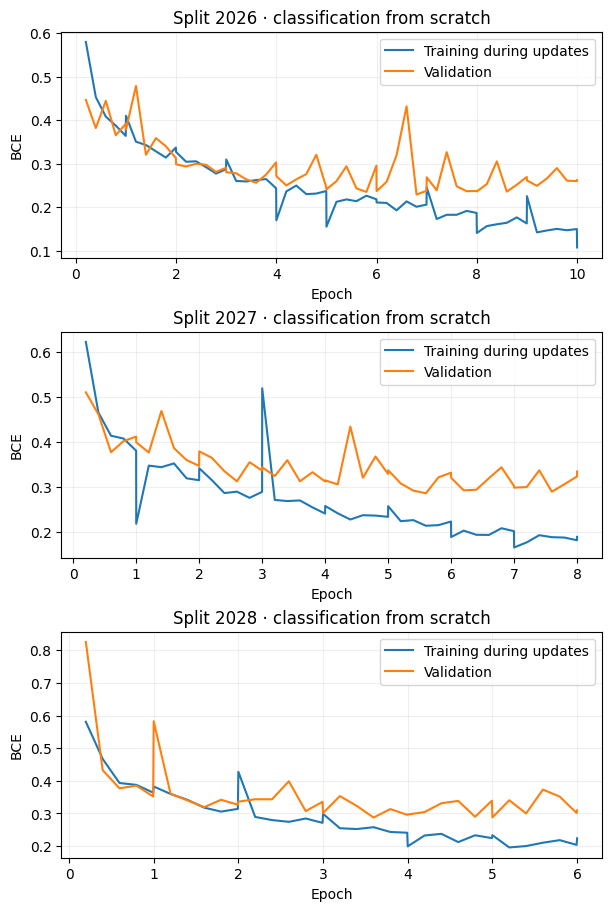

In [11]:
fig, axes = plt.subplots(len(SEEDS), 1, figsize=(6, 3 * len(SEEDS)), squeeze=False, layout="constrained")
for row, seed in enumerate(SEEDS):
    history = json.loads((OUT / f"split{seed}" / "from_scratch" / "classification" / "history.json").read_text())
    epochs = [h["epoch"] for h in history]
    ax = axes[row, 0]
    ax.plot(epochs, [h["train_loss"] for h in history], label="Training during updates")
    ax.plot(epochs, [h["validation"]["loss"] for h in history], label="Validation")
    ax.set(title=f"Split {seed} · classification from scratch", xlabel="Epoch", ylabel="BCE")
    ax.grid(alpha=.2)
    ax.legend()
fig.savefig(OUT / "loss_curves_from_scratch.png", dpi=160)
plt.show()
